In [1]:
from flowlenia.analysis.ea import compute_ea_data
from flowlenia.analysis.genomes import compute_genome_data
from flowlenia.simutils import load_files
from flowlenia.flowlenia_params import Config

from jax import numpy as jnp
import numpy as np
from flowlenia.utils import conn_from_matrix

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
seeds = [0, 1, 2, 3, 4]
cells = [1, 2, 3, 4]
n_step = 25000
save_interval = 250
X, Y = 512, 512
do_wall = True
do_connected = True
log_full = False

M = np.array([[2, 1, 0], [0, 2, 1], [1, 0, 2]])
k = M.sum()
c0, c1 = conn_from_matrix(M)
cfg = Config(X=X, Y=Y, C=3, k=k, c0=c0, c1=c1)

ea_data = pd.DataFrame(columns=["seed", "Number of cells", "Type of map", "t", "A_p", "A_c", "A_n", "delta_p", "delta_c", "delta_n"])

In [3]:
for n_cells in cells:
    for seed in seeds:
        print(f"Running seed {seed} with {n_cells} cells")

        data = load_files(f"../../exp_data/walls/{n_cells}_walls/{seed}")
        genome_data = compute_genome_data(data)
        ea = compute_ea_data(genome_data, return_a=True, return_deltas=True)
        for t in range(len(ea.A_p)):
            row = {
                "seed": seed,
                "Number of cells": 4**(n_cells-1),
                "Type of map": "Disconnected",
                "t": t*save_interval,
                "A_p": ea.A_p[t],
                "A_c": ea.A_c[t],
                "A_n": ea.A_n[t],
                "delta_p": ea.delta_p[t].sum(),
                "delta_c": ea.delta_c[t].sum(),
                "delta_n": ea.delta_n[t].sum()
            }
            ea_data = pd.concat([ea_data, pd.DataFrame([row])], ignore_index=True)

Running seed 0 with 1 cells


100%|██████████| 101/101 [00:10<00:00,  9.51it/s]


Running seed 1 with 1 cells


100%|██████████| 101/101 [00:05<00:00, 18.44it/s]


Running seed 2 with 1 cells


100%|██████████| 101/101 [00:07<00:00, 13.58it/s]


... (30 outputs left out)

Running seed 3 with 4 cells


100%|██████████| 101/101 [00:00<00:00, 691.28it/s]


Running seed 4 with 4 cells


100%|██████████| 101/101 [00:00<00:00, 2686.54it/s]


In [4]:
for n_cells in cells:
    for seed in seeds:
        print(f"Running seed {seed} with {n_cells} cells")

        data = load_files(f"../../exp_data/walls/{n_cells}_connected/{seed}")
        genome_data = compute_genome_data(data)
        ea = compute_ea_data(genome_data, return_a=True, return_deltas=True)
        for t in range(len(ea.A_p)):
            row = {
                "seed": seed,
                "Number of cells": 4**(n_cells-1),
                "Type of map": "Connected",
                "t": t*save_interval,
                "A_p": ea.A_p[t],
                "A_c": ea.A_c[t],
                "A_n": ea.A_n[t],
                "delta_p": ea.delta_p[t].sum(),
                "delta_c": ea.delta_c[t].sum(),
                "delta_n": ea.delta_n[t].sum()
            }
            ea_data = pd.concat([ea_data, pd.DataFrame([row])], ignore_index=True)

Running seed 0 with 1 cells


100%|██████████| 101/101 [00:01<00:00, 88.56it/s]


Running seed 1 with 1 cells


100%|██████████| 101/101 [00:01<00:00, 76.96it/s]


Running seed 2 with 1 cells


100%|██████████| 101/101 [00:00<00:00, 149.07it/s]


... (30 outputs left out)

Running seed 3 with 4 cells


100%|██████████| 101/101 [00:00<00:00, 2409.01it/s]


Running seed 4 with 4 cells


100%|██████████| 101/101 [00:00<00:00, 2642.34it/s]


In [5]:

ea_data.head()

,seed,Number of cells,Type of map,t,A_p,A_c,A_n,delta_p,delta_c,delta_n
0,0,1,Disconnected,0,0.0,0.000000,0.000000,0.0,0.000000,0.000000
1,0,1,Disconnected,250,65.0,24694.023575,0.344794,65.0,24694.023575,0.344794
2,0,1,Disconnected,500,135.0,49387.161677,0.743619,70.0,24693.138102,0.398824
3,0,1,Disconnected,750,207.0,74079.388411,2.332271,72.0,24692.226734,1.588653
4,0,1,Disconnected,1000,286.0,98770.392006,3.157483,81.0,24691.313676,0.825213


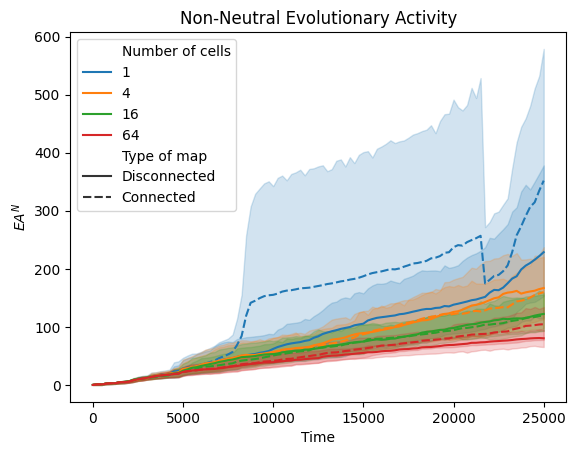

In [6]:
sns.lineplot(data=ea_data, x="t", y="A_n", hue="Number of cells", style="Type of map", palette="tab10")
plt.title("Non-Neutral Evolutionary Activity")
plt.ylabel("$EA^N$")
plt.xlabel("Time")
plt.savefig("ea_n_new.png")

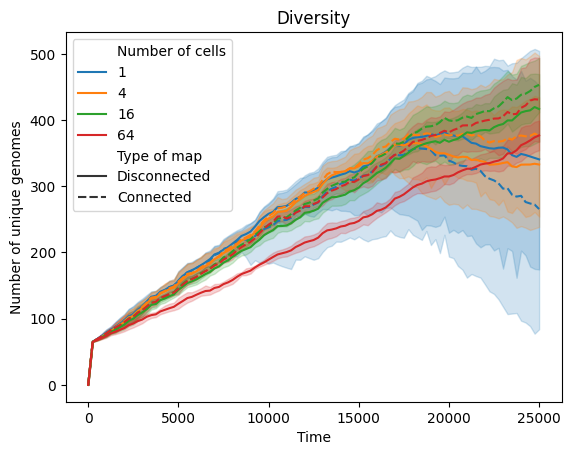

In [7]:
sns.lineplot(data=ea_data, x="t", y="delta_p", hue="Number of cells", style="Type of map", palette="tab10")
plt.title("Diversity")
plt.ylabel("Number of unique genomes")
plt.xlabel("Time")
plt.savefig("diversity_new.png")

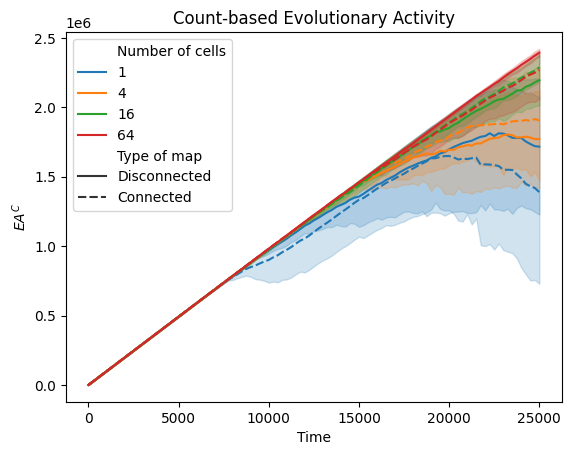

In [8]:
sns.lineplot(data=ea_data, x="t", y="A_c", hue="Number of cells", style="Type of map", palette="tab10")
plt.title("Count-based Evolutionary Activity")
plt.ylabel("$EA^C$")
plt.xlabel("Time")
plt.savefig("ea_c_new.png")

<Axes: xlabel='Number of cells', ylabel='delta_n'>

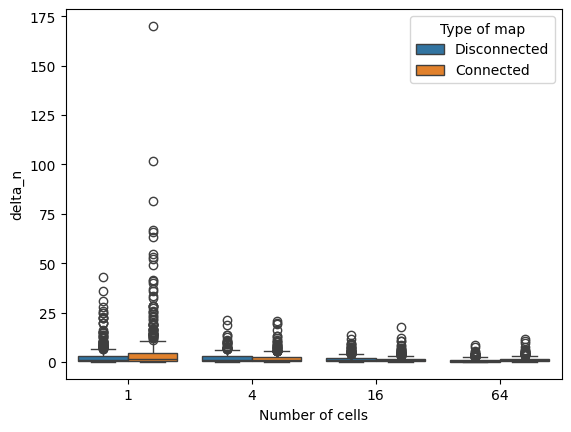

In [9]:
sns.boxplot(data=ea_data, x="Number of cells", y="delta_n", hue="Type of map", palette="tab10")

Text(0.5, 0, 'Time')

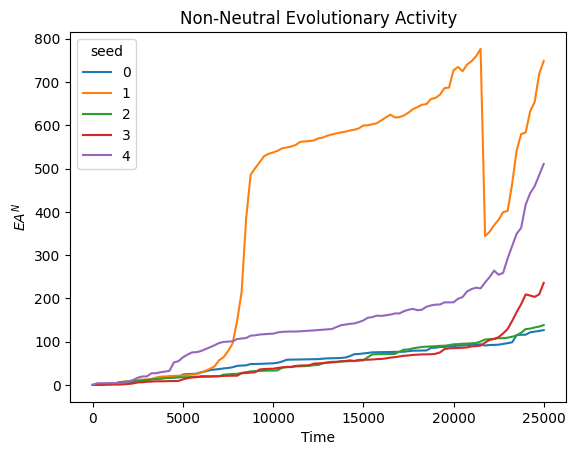

In [10]:
sns.lineplot(data=ea_data[ea_data["Number of cells"] == 1][ea_data["Type of map"] == "Connected"], x="t", y="A_n", hue="seed",palette="tab10")
plt.title("Non-Neutral Evolutionary Activity")
plt.ylabel("$EA^N$")
plt.xlabel("Time")
#plt.savefig("particular_ea.png")

## Jumping seed

dict_keys(['uP', 'cP', 'iP', 'A'])


100%|██████████| 101/101 [00:00<00:00, 2817.44it/s]


Text(0.5, 0, 'Time')

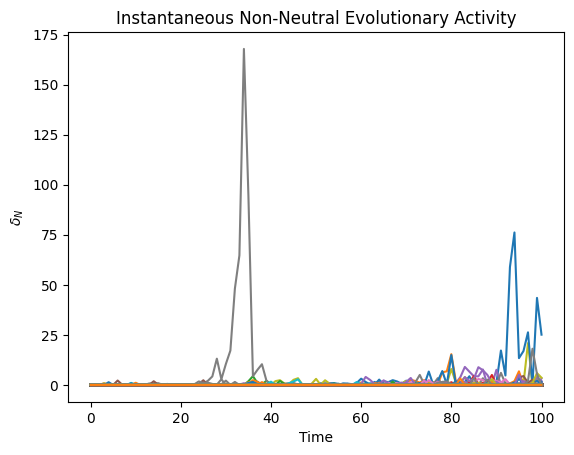

In [11]:
data = load_files("../../exp_data/walls/1_connected/1")
print(data[0].keys())
genome_data = compute_genome_data(data)
ea = compute_ea_data(genome_data, return_a=True, return_deltas=True)

m = 0
k = 0
for t in range(len(ea.A_p)):
    if jnp.max(ea.delta_n[t]) > m:
        k = jnp.argmax(ea.delta_n[t])
        m = ea.delta_n[t][k]

for key in range(ea.delta_n.shape[1]):
    sns.lineplot(ea.delta_n[:, key])

plt.title("Instantaneous Non-Neutral Evolutionary Activity")
plt.ylabel("$\delta_N$")
plt.xlabel("Time")
#plt.savefig("delta_n_new_one_run.png")

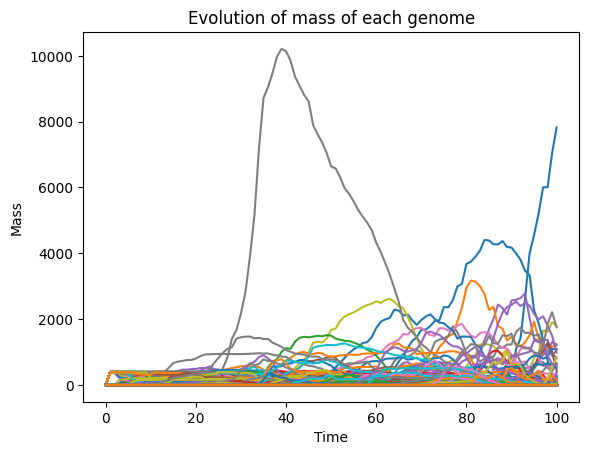

In [12]:
for key in range(ea.delta_n.shape[1]):
    sns.lineplot(ea.delta_c[:, key])

plt.title("Evolution of mass of each genome")
plt.ylabel("Mass")
plt.xlabel("Time")
plt.savefig("delta_c_new_one_run.png")

Text(0.5, 1.0, 'Non-neutral activity and genome mass')

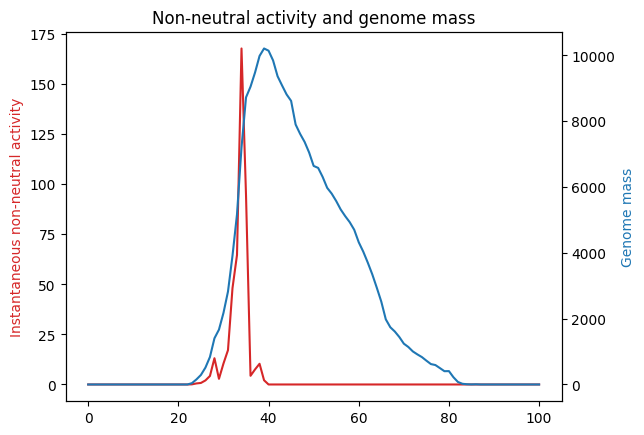

In [13]:
fig, ax1 = plt.subplots()
color1 = 'tab:red'
sns.lineplot(ea.delta_n[:, k], ax=ax1, color=color1)
ax2 = ax1.twinx()
color2 = 'tab:blue'
sns.lineplot(ea.delta_c[:, k], ax=ax2, color=color2)
ax1.set_ylabel("Instantaneous non-neutral activity", color=color1)
ax2.set_ylabel("Genome mass", color=color2)
plt.xlabel("Time")
plt.title("Non-neutral activity and genome mass")
#plt.savefig("ea_n_genome_mass_one_run.png")

Text(0.5, 0, 'Time')

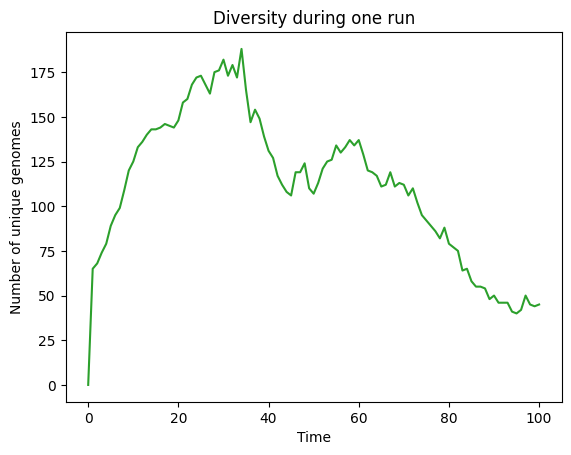

In [14]:
sns.lineplot(ea.delta_p.sum(axis=1), color="tab:green")
plt.title("Diversity during one run")
plt.ylabel("Number of unique genomes")
plt.xlabel("Time")
#plt.savefig("diversity_one_run.png")

## Another seed

dict_keys(['uP', 'cP', 'iP', 'A'])


100%|██████████| 101/101 [00:00<00:00, 1775.79it/s]


<function matplotlib.pyplot.savefig(*args, **kwargs) -> 'None'>

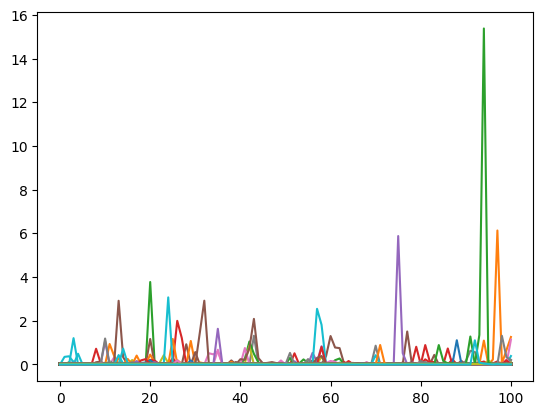

In [15]:
data = load_files("../../exp_data/walls/1_connected/0")
print(data[0].keys())
genome_data = compute_genome_data(data)
ea = compute_ea_data(genome_data, return_a=True, return_deltas=True)

m = 0
k = 0
for t in range(len(ea.A_p)):
    if jnp.max(ea.delta_n[t]) > m:
        k = jnp.argmax(ea.delta_n[t])
        m = ea.delta_n[t][k]

for key in range(ea.delta_n.shape[1]):
    sns.lineplot(ea.delta_n[:, key])
plt.savefig

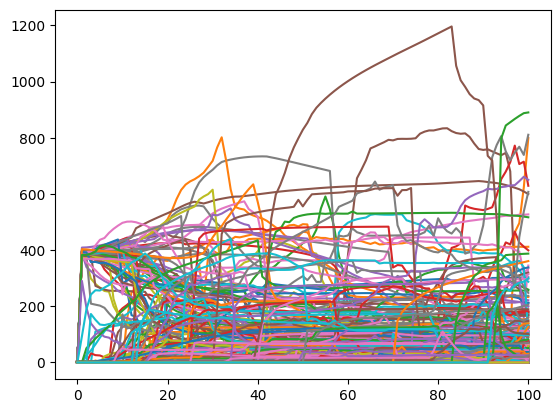

In [16]:
for key in range(ea.delta_n.shape[1]):
    sns.lineplot(ea.delta_c[:, key])

## All seeds

Text(0.5, 1.0, 'Diversity')

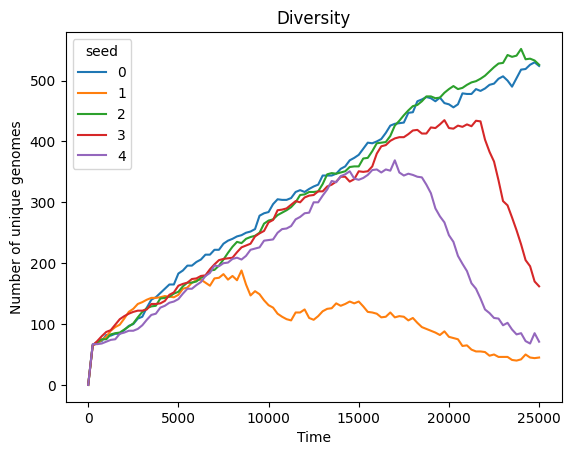

In [17]:
sns.lineplot(data=ea_data[ea_data["Number of cells"] == 1][ea_data["Type of map"] == "Connected"], x="t", y="delta_p", hue="seed",palette="tab10")
plt.ylabel("Number of unique genomes")
plt.xlabel("Time")
plt.title("Diversity")
#plt.savefig("particular_diversity.png")